# NGC 4654 maximum SFR-excess contrast

Use the continuum-bin excesses defined in the [Fourier/VIVA notebook](20261117_NGC4654_SFR_excess_Fourier_VIVA.ipynb). The input and calibration cells reproduce its 7000-run SF selection, equal-galaxy pre-peak rSFMS and width $W$. Each continuum `BINID` contributes one mean normalized residual $E=(\log\Sigma_{\rm SFR}-\log\Sigma_{\rm SFR,ref})/W$ over its selected SF spaxels. The centroid and elliptical radius use all native pixels in the bin.

Following the [radial-matched anisotropy discussion](https://chatgpt.com/c/6afc1ff2-27c0-83ec-aeaf-949c55d6b7df), a line through the galaxy centre divides the map into opposite halves. Its normal points at projected PA $\theta$, east of north, toward $H_+(\theta)$. Within each of the four $0.5R_e$ annuli from 0 to $2R_e$, take the difference between the two arithmetic means of $E$, with each continuum bin weighted equally within its half. The four annular contrasts receive equal weight.

$$
H_\pm(\theta)=\{i:\ \pm\cos(\phi_i-\theta)>0\},\qquad
D(\theta)=\frac{1}{4}\sum_{a=1}^4\left(\overline E_{a,+}-\overline E_{a,-}\right),\qquad
\theta_{\max}=\arg\max_\theta D(\theta).
$$

This is a descriptive direction for the selected SF bins. A higher contrast can arise from higher residuals in $H_+$ or lower residuals in $H_-$. $D_{\max}$ is in units of $W$. A spatial-block bootstrap and a spatially calibrated null test would be needed for uncertainty and significance, respectively.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}

ANNULUS_EDGES = np.arange(5) * 0.5
MIN_BINS_PER_HALF = 5  # Require this many continuum bins in each half of each annulus.

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 22, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/Igniz/.cache/fontconfig
	/Users/Igniz/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/Igniz/.cache/fontconfig
	/Users/Igniz/.fontconfig


Matplotlib is building the font cache; this may take a moment.


In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component):
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    east, north = tangent_offsets_arcsec(
        ra, dec, component.center_ra_deg, component.center_dec_deg
    )
    return elliptical_radius_from_offsets(east, north, component)


def elliptical_radius_from_offsets(east, north, component):
    pa = np.deg2rad(float(component.pa_deg_east_of_north))
    major = east * np.sin(pa) + north * np.cos(pa)
    minor = east * np.cos(pa) - north * np.sin(pa)
    return np.sqrt((major / float(component.a_re_arcsec)) ** 2
                   + (minor / float(component.b_re_arcsec)) ** 2)


def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    gas_arrays['LOGSFR_SURFACE_DENSITY_HII'] += delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


In [3]:
# Only load the pre-peak reference sample and the NGC4654 target.
def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        if all(geometry_by_galaxy.loc[g, 'stage_code'] != 1 and g != 'NGC4654' for g in components):
            continue
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            if component.stage_code != 1 and galaxy != 'NGC4654':
                continue
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths

sf_x_parts, sf_y_parts, sf_group_parts, sf_error_parts = [], [], [], []
inventory_rows, count_rows = [], []
ngc4654_sf_geometry = None
ngc4654_bin_geometry = None
ngc4654_native_binid = None
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,product_id=product_id,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR',
            'HA6562_FLUX_CORR', 'HA6562_FLUX_ERR_CORR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    apply_component_inclination(product_id, component, mass, arrays)
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    assert not np.any(sf & ~balmer), f'{gal}: SF overlaps Balmer ND'
    group_id = len(count_rows)
    sf_x_parts.append(mass[sf])
    sf_y_parts.append(sfr[sf])
    sf_group_parts.append(np.full(int(sf.sum()), group_id, dtype=np.int16))
    if gal == 'NGC4654':
        radius_re = calculate_deprojected_radius(mass.shape, mass_hdr, component)
        assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
        continuum_binid, binid_hdr = read_map(paths['mass'], 'BINID')
        if continuum_binid.shape != sf.shape:
            raise ValueError(f'{gal}: continuum BINID and SF mask shapes differ')
        check_wcs(mass_hdr, binid_hdr, sf.shape, f'{gal} mass/continuum BINID')
        pixel_y, pixel_x = np.nonzero(sf)
        ra, dec = WCS(mass_hdr).celestial.pixel_to_world_values(pixel_x, pixel_y)
        east, north = tangent_offsets_arcsec(ra, dec, component.center_ra_deg, component.center_dec_deg)
        ngc4654_sf_geometry = pd.DataFrame(dict(east=east, north=north,
            r=radius_re[sf], binid=continuum_binid[sf]), index=np.flatnonzero(sf))
        # Use every native pixel in each continuum BINID, including non-SF pixels.
        native = (np.isfinite(continuum_binid) & (continuum_binid >= 0)
                  & (continuum_binid == np.floor(continuum_binid)))
        native_y, native_x = np.nonzero(native)
        native_ra, native_dec = WCS(mass_hdr).celestial.pixel_to_world_values(native_x, native_y)
        native_east, native_north = tangent_offsets_arcsec(
            native_ra, native_dec, component.center_ra_deg, component.center_dec_deg)
        bin_ids, bin_index, bin_count = np.unique(
            continuum_binid[native].astype(np.int64), return_inverse=True, return_counts=True)
        centre_east = np.bincount(bin_index, weights=native_east) / bin_count
        centre_north = np.bincount(bin_index, weights=native_north) / bin_count
        ngc4654_bin_geometry = pd.DataFrame(dict(
            binid=bin_ids, east=centre_east, north=centre_north, N_native=bin_count,
            r=elliptical_radius_from_offsets(centre_east, centre_north, component)))
        ngc4654_native_binid = continuum_binid
    # Paired Halpha errors for the source excess-width recipe, in the same SF order.
    ha_flux_sf = arrays['HA6562_FLUX_CORR'][sf]
    ha_error_sf = arrays['HA6562_FLUX_ERR_CORR'][sf]
    ha_error_ok = np.isfinite(ha_flux_sf) & (ha_flux_sf > 0) & np.isfinite(ha_error_sf) & (ha_error_sf >= 0)
    sf_error_dex = np.full(len(ha_flux_sf), np.nan)
    sf_error_dex[ha_error_ok] = ha_error_sf[ha_error_ok] / ha_flux_sf[ha_error_ok] / np.log(10.0)
    sf_error_parts.append(sf_error_dex)
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                           usable=int(valid.sum()), SF=int(sf.sum())))

if not count_rows:
    raise RuntimeError('No complete Paper II product sets found for NGC4654 or the pre-peak reference')
inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
sf_x, sf_y, sf_group = (np.concatenate(parts) for parts in (sf_x_parts, sf_y_parts, sf_group_parts))
assert sf_x.size == sf_y.size == sf_group.size == counts.SF.sum()
display(inventory[['galaxy', 'product_id', 'stage', 'inclination', 'status']])
display(counts)

,galaxy,product_id,stage,inclination,status
0,NGC4189,NGC4189,1,42.0,included
1,NGC4192,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
2,NGC4222,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
3,NGC4254,NGC4254,1,39.0,included
4,NGC4294,NGC4294,1,74.0,included
5,NGC4321,NGC4321,1,32.0,included
6,NGC4351,NGC4351,1,48.0,included
7,NGC4383,NGC4383,1,56.0,included
8,NGC4396,NGC4396,1,83.0,excluded: inclination >=80 or unavailable
9,NGC4535,NGC4535,1,48.0,included


,galaxy,stage,inclination,usable,SF
0,NGC4189,1,42.0,134346,88582
1,NGC4254,1,39.0,615883,453580
2,NGC4294,1,74.0,125185,66537
3,NGC4321,1,32.0,808599,382821
4,NGC4351,1,48.0,98128,29767
5,NGC4383,1,56.0,62174,15627
6,NGC4535,1,48.0,459337,161648
7,NGC4567,1,49.0,175337,87590
8,NGC4568,1,70.0,218439,114364
9,NGC4654,2,61.0,555079,325678


In [4]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])

sf_stage = counts.stage.to_numpy(int)[sf_group]
assert (sf_stage == 1).any(), 'No pre-peak SF reference products'
pre=sf_stage==1
pre_peak_fit=equal_galaxy_ols(sf_x[pre],sf_y[pre],sf_group[pre])

assert counts.inclination.lt(INCLINATION_MAX).all()
excess_meta = counts.reset_index(drop=True)
target = excess_meta.loc[excess_meta.galaxy.eq('NGC4654')]
if len(target) != 1 or int(target.iloc[0].SF) == 0:
    raise ValueError('NGC4654: not available with SF spaxels after the global cuts; inspect inventory')
assert int(target.iloc[0].stage) == 2, 'NGC4654: unexpected catalogue stage'
excess_errors = np.concatenate(sf_error_parts)
assert len(excess_errors) == len(sf_x) == len(sf_y) == len(sf_group)
excess_reference = pre_peak_fit['slope'] * sf_x + pre_peak_fit['intercept']
excess_residuals = sf_y - excess_reference
excess_pre_ids = excess_meta.index[(excess_meta.stage == 1) & (excess_meta.SF > 0)].to_numpy()
assert len(excess_pre_ids), 'No pre-peak SF reference products'
excess_width_rows = []
for group_id in excess_pre_ids:
    selected = (sf_group == group_id) & np.isfinite(excess_errors) & (excess_errors >= 0)
    assert selected.any(), f'{excess_meta.loc[group_id, "galaxy"]}: no finite errors for width'
    radicand = excess_residuals[selected]**2 - excess_errors[selected]**2
    excess_width_rows.append(dict(galaxy=excess_meta.loc[group_id, 'galaxy'],
        N_width=int(selected.sum()), width_dex=float(np.sqrt(np.maximum(radicand, 0)).mean()),
        fraction_clipped_to_zero=float((radicand <= 0).mean())))
excess_width_by_galaxy = pd.DataFrame(excess_width_rows)
excess_width = float(excess_width_by_galaxy.width_dex.mean())
assert np.isfinite(excess_width) and excess_width > 0
excess_values = excess_residuals / excess_width

display(excess_width_by_galaxy)
print(f'Pre-peak equal-galaxy reference: y={pre_peak_fit["slope"]:.6f}x{pre_peak_fit["intercept"]:+.6f}; W={excess_width:.6f} dex')

,galaxy,N_width,width_dex,fraction_clipped_to_zero
0,NGC4189,88582,0.359797,0.027974
1,NGC4254,453580,0.447343,0.028438
2,NGC4294,66537,0.357248,0.014188
3,NGC4321,382821,0.389444,0.029442
4,NGC4351,29767,0.366184,0.017402
5,NGC4383,15627,0.444388,0.018878
6,NGC4535,161648,0.464960,0.016307
7,NGC4567,87590,0.335900,0.039034
8,NGC4568,114364,0.358164,0.042076


Pre-peak equal-galaxy reference: y=0.748260x-7.992286; W=0.391492 dex


## Continuum-bin excess map

The source map is collapsed to its native continuum bins before applying the new radial range. The analysis assigns each bin to an annulus and half by its centroid, including when its footprint crosses either boundary.

In [5]:
ngc4654_group = int(excess_meta.index[excess_meta.galaxy.eq('NGC4654')].item())
ngc4654_excess = excess_values[sf_group == ngc4654_group]
if ngc4654_sf_geometry is None or len(ngc4654_sf_geometry) != ngc4654_excess.size:
    raise ValueError('Rerun the input and calibration cells to align the NGC4654 geometry and SF residuals.')
ngc4654_map = ngc4654_sf_geometry.assign(excess=ngc4654_excess)
valid_binid = (np.isfinite(ngc4654_map.binid) & (ngc4654_map.binid >= 0)
               & (ngc4654_map.binid == np.floor(ngc4654_map.binid)))
ngc4654_bin_excess = (ngc4654_map.loc[valid_binid].groupby('binid').excess
                     .agg(excess='mean', N_SF='size').reset_index())
ngc4654_bins = ngc4654_bin_geometry.merge(ngc4654_bin_excess, on='binid', validate='one_to_one')
assert ngc4654_bins.N_SF.sum() == valid_binid.sum()
assert ngc4654_bins.N_SF.le(ngc4654_bins.N_native).all()

ngc4654_bins['phi_deg'] = np.degrees(
    np.arctan2(ngc4654_bins.east, ngc4654_bins.north)) % 360
in_aperture = (np.isfinite(ngc4654_bins.excess)
               & np.isfinite(ngc4654_bins.phi_deg)
               & (np.hypot(ngc4654_bins.east, ngc4654_bins.north) > 0)
               & ngc4654_bins.r.between(ANNULUS_EDGES[0], ANNULUS_EDGES[-1]))
cut_bins = ngc4654_bins.loc[in_aperture].copy()
cut_bins['annulus'] = np.minimum(
    np.searchsorted(ANNULUS_EDGES, cut_bins.r, side='right') - 1,
    len(ANNULUS_EDGES) - 2)
assert cut_bins.binid.is_unique
print(f'{len(cut_bins):,} continuum bins within 2 Re, from {cut_bins.N_SF.sum():,} SF spaxels')

17,298 continuum bins within 2 Re, from 321,887 SF spaxels


## Search every distinct half-map cut

Bin membership changes only at $\theta=\phi_i\pm90^\circ$. Evaluate the open intervals between successive crossing angles, including the interval that wraps across north. Each interval represents one fixed partition. We report all intervals tied for the maximum within numerical tolerance and use the midpoint of the widest as the representative PA. The interval bounds describe the partition and carry no confidence level.

At each angle both halves of all four annuli must contain at least `MIN_BINS_PER_HALF` bins, set to five as a coverage floor for the descriptive estimate.

In [6]:
def scan_half_cuts(bins, n_annuli):
    """Compute half counts and means on all open angular intervals."""
    if bins.empty:
        raise ValueError('No continuum bins with finite excess and sky PA within the aperture.')
    phi = bins.phi_deg.to_numpy()
    # Merge coincident events up to floating-point precision in sky PA.
    boundaries = np.unique(np.round((phi + 90) % 180, 10) % 180)
    boundaries = np.concatenate([boundaries, boundaries + 180])
    right_edges = np.r_[boundaries[1:], boundaries[0] + 360]
    midpoints = ((boundaries + right_edges) / 2) % 360
    half_start = (midpoints - 90) % 360
    half_end = half_start + 180

    n_plus = np.zeros((len(midpoints), n_annuli), dtype=int)
    n_minus = np.zeros_like(n_plus)
    mean_plus = np.full(n_plus.shape, np.nan)
    mean_minus = np.full_like(mean_plus, np.nan)
    for annulus in range(n_annuli):
        ring = bins.loc[bins.annulus == annulus].sort_values('phi_deg')
        angles = ring.phi_deg.to_numpy()
        values = ring.excess.to_numpy()
        angles = np.r_[angles, angles + 360]
        cumulative = np.r_[0.0, np.cumsum(np.tile(values, 2))]
        start = np.searchsorted(angles, half_start, side='right')
        stop = np.searchsorted(angles, half_end, side='left')
        n_plus[:, annulus] = stop - start
        n_minus[:, annulus] = len(ring) - n_plus[:, annulus]
        sum_plus = cumulative[stop] - cumulative[start]
        np.divide(sum_plus, n_plus[:, annulus],
                  out=mean_plus[:, annulus], where=n_plus[:, annulus] > 0)
        np.divide(values.sum() - sum_plus, n_minus[:, annulus],
                  out=mean_minus[:, annulus], where=n_minus[:, annulus] > 0)

    cuts = pd.DataFrame({
        'start_deg': boundaries,
        'end_deg': right_edges,
        'theta_deg': midpoints,
        'width_deg': right_edges - boundaries,
        'D_W': (mean_plus - mean_minus).mean(axis=1),
        'min_half_count': np.minimum(n_plus, n_minus).min(axis=1),
    })
    return cuts, n_plus, n_minus, mean_plus, mean_minus


def maximizing_intervals(cuts, min_bins):
    eligible = cuts.loc[cuts.min_half_count >= min_bins]
    if eligible.empty:
        raise ValueError(f'No cut has at least {min_bins} bins in both halves of all annuli.')
    peak = eligible.D_W.max()
    return eligible.loc[np.isclose(eligible.D_W, peak, rtol=0, atol=1e-12)].sort_values(
        ['width_deg', 'start_deg'], ascending=[False, True])


n_annuli = len(ANNULUS_EDGES) - 1
cuts, n_plus, n_minus, mean_plus, mean_minus = scan_half_cuts(cut_bins, n_annuli)
max_intervals = maximizing_intervals(cuts, MIN_BINS_PER_HALF)
best = max_intervals.index[0]
theta_max = float(cuts.at[best, 'theta_deg'])
D_max = float(cuts.at[best, 'D_W'])
eligible_cuts = cuts.min_half_count >= MIN_BINS_PER_HALF

# Verify the reported interval against direct centroid membership.
selected_plus = np.cos(np.deg2rad(cut_bins.phi_deg - theta_max)) > 0
for annulus in range(n_annuli):
    ring = cut_bins.annulus == annulus
    for selected, count, mean in (
        (selected_plus, n_plus, mean_plus), (~selected_plus, n_minus, mean_minus)
    ):
        values = cut_bins.loc[ring & selected, 'excess']
        assert len(values) == count[best, annulus]
        np.testing.assert_allclose(values.mean(), mean[best, annulus], atol=1e-12, rtol=0)

print(f'theta_max = {theta_max:.4f} deg east of north')
print(f'D_max = {D_max:.6f} W ({D_max * excess_width:.6f} dex residual contrast)')
print(f'{eligible_cuts.sum():,} of {len(cuts):,} angular intervals meet the coverage floor.')
display(max_intervals[['start_deg', 'end_deg', 'theta_deg', 'width_deg', 'D_W']])
print('Annular means and counts at theta_max')
annular_contrast = pd.DataFrame({
    'R/Re': [f'{lo:.1f}-{hi:.1f}' for lo, hi in zip(ANNULUS_EDGES[:-1], ANNULUS_EDGES[1:])],
    'N_plus': n_plus[best], 'N_minus': n_minus[best],
    'mean_E_plus': mean_plus[best], 'mean_E_minus': mean_minus[best],
    'D_W': mean_plus[best] - mean_minus[best],
})
display(annular_contrast)

theta_max = 319.4051 deg east of north
D_max = 0.456352 W (0.178658 dex residual contrast)
34,596 of 34,596 angular intervals meet the coverage floor.


,start_deg,end_deg,theta_deg,width_deg,D_W
32323,319.389999,319.420172,319.405085,0.030173,0.456352


Annular means and counts at theta_max


,R/Re,N_plus,N_minus,mean_E_plus,mean_E_minus,D_W
0,0.0-0.5,2979,3065,0.222122,-0.063291,0.285413
1,0.5-1.0,3525,3467,0.075690,-0.080659,0.156349
2,1.0-1.5,2412,1180,0.402497,-0.595687,0.998184
3,1.5-2.0,295,375,-0.169477,-0.554939,0.385462


## Bin map and angular contrast

The displayed footprints carry their bin's mean residual. The line and arrow mark the maximizing cut and its normal. Gaps in the step curve indicate cuts that fail the coverage floor.

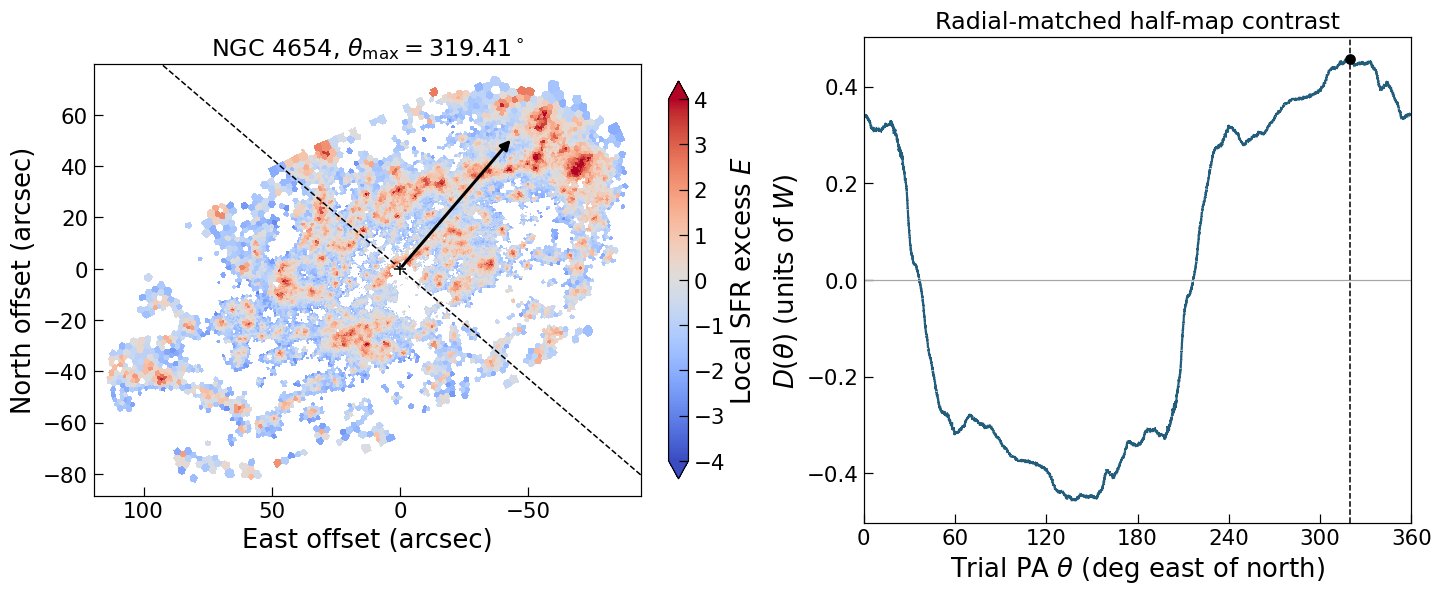

In [7]:
# Paint the included bins on their native FITS grid for display.
bin_map = np.full(ngc4654_native_binid.shape, np.nan)
in_fit_bin = np.isin(ngc4654_native_binid, cut_bins.binid)
excess_by_bin = cut_bins.set_index('binid').excess
bin_map[in_fit_bin] = excess_by_bin.loc[ngc4654_native_binid[in_fit_bin]].to_numpy()

# Convert the native pixel corners to the same tangent plane used by the cut.
ny, nx = bin_map.shape
pixel_x, pixel_y = np.meshgrid(np.arange(nx + 1) - 0.5, np.arange(ny + 1) - 0.5)
ra, dec = WCS(binid_hdr).celestial.pixel_to_world_values(pixel_x, pixel_y)
centre = geometry_by_galaxy.loc['NGC4654']
east, north = tangent_offsets_arcsec(ra, dec, centre.center_ra_deg, centre.center_dec_deg)

fig, (ax_map, ax_curve) = plt.subplots(1, 2, figsize=(13, 5.3), layout='constrained')
mesh = ax_map.pcolormesh(east, north, bin_map, cmap='coolwarm', vmin=-4, vmax=4,
                         shading='flat', rasterized=True)
fig.colorbar(mesh, ax=ax_map, label=r'Local SFR excess $E$', extend='both', shrink=0.82)

theta = np.deg2rad(theta_max)
extent = np.hypot(cut_bins.east, cut_bins.north).max()
along_line = np.array([-2, 2]) * extent
ax_map.plot(along_line * np.cos(theta), -along_line * np.sin(theta),
            'k--', lw=1, label='Dividing line')
ax_map.annotate('', xy=0.55 * extent * np.array([np.sin(theta), np.cos(theta)]),
                xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', lw=2, color='black'))
ax_map.plot(0, 0, 'k+', ms=8)
yy, xx = np.nonzero(in_fit_bin)
margin = 5
ax_map.set(aspect='equal', xlim=(east[yy, xx].max() + margin, east[yy, xx].min() - margin),
           ylim=(north[yy, xx].min() - margin, north[yy, xx].max() + margin),
           xlabel='East offset (arcsec)', ylabel='North offset (arcsec)',
           title=rf'NGC 4654, $\theta_{{\max}}={theta_max:.2f}^\circ$')

curve = cuts.D_W.where(eligible_cuts).to_numpy()
plot_edges = np.r_[0, cuts.start_deg, 360]
plot_values = np.r_[curve[-1], curve]
ax_curve.stairs(plot_values, plot_edges, baseline=None, color='#235d7c', linewidth=1.4)
ax_curve.axhline(0, color='0.65', linewidth=0.8)
ax_curve.axvline(theta_max, color='black', linestyle='--', linewidth=1)
ax_curve.scatter(theta_max, D_max, color='black', zorder=3)
ax_curve.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
             xlabel=r'Trial PA $\theta$ (deg east of north)', ylabel=r'$D(\theta)$ (units of $W$)',
             title='Radial-matched half-map contrast')
plt.show()